In [6]:
import pandas as pd, numpy as np, re, zipfile
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

zip_path = "/Users/hansamali/Desktop/ai&ml/pusl3123-ai-ml-coursework/pusl3123-ai-ml-coursework/assesment_cifar10/LLM-Practical-Portfolio/Lab-01-Machine-Learning/sentiment+labelled+sentences.zip"
z = zipfile.ZipFile(zip_path)
frames = []
for name in z.namelist():
    if name.endswith("_labelled.txt"):
        d = pd.read_csv(z.open(name), sep="\t", header=None, names=["text", "label"],
                        encoding="latin-1", quoting=3)
        d["source"] = name.split("/")[-1].split("_")[0]
        frames.append(d)
df = pd.concat(frames, ignore_index=True)
print(df.shape); print(df.head()); print(df.label.value_counts())

(3001, 3)
                                                text  label  source
0  So there is no way for me to plug it in here i...    0.0  amazon
1                        Good case, Excellent value.    1.0  amazon
2                             Great for the jawbone.    1.0  amazon
3  Tied to charger for conversations lasting more...    0.0  amazon
4                                  The mic is great.    1.0  amazon
label
0.0    1500
1.0    1500
Name: count, dtype: int64


In [7]:
def clean(t):
    t = str(t).lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean_text"] = df["text"].apply(clean)
df[["text", "clean_text"]].sample(5, random_state=1)

,text,clean_text
929,As I said above....PRETTY USELESS!,as i said above pretty useless
1422,I just cant explain this movie more than roman...,i just cant explain this movie more than roman...
1100,I don't think you will be disappointed.,i don t think you will be disappointed
2541,I had the opportunity today to sample your ama...,i had the opportunity today to sample your ama...
393,"Excellent product, I am very satisfied with th...",excellent product i am very satisfied with the...


POSITIVE:
 1                     Good case, Excellent value.
2                          Great for the jawbone.
4                               The mic is great.
7     If you are Razr owner...you must have this!
10                And the sound quality is great.

NEGATIVE:
 0    So there is no way for me to plug it in here i...
3    Tied to charger for conversations lasting more...
5    I have to jiggle the plug to get it to line up...
6    If you have several dozen or several hundred c...
8                  Needless to say, I wasted my money.
Positive [('great', 201), ('good', 178), ('s', 148), ('film', 105), ('phone', 88), ('movie', 86), ('t', 65), ('best', 63), ('food', 60), ('place', 58)]


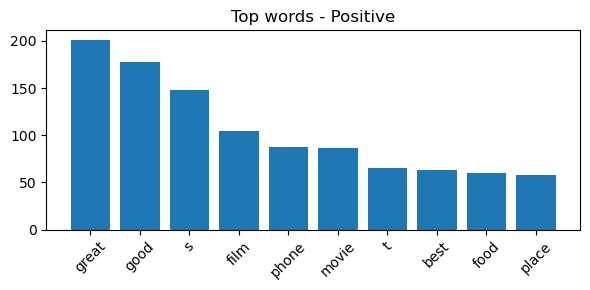

Negative [('t', 216), ('s', 112), ('bad', 100), ('movie', 96), ('phone', 80), ('like', 69), ('just', 66), ('food', 66), ('don', 64), ('time', 62)]


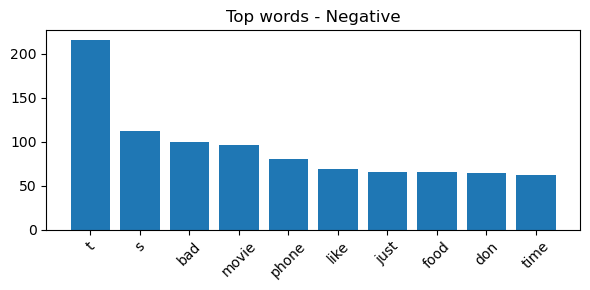

In [8]:
print("POSITIVE:\n", df[df.label == 1].text.head(5).to_string())
print("\nNEGATIVE:\n", df[df.label == 0].text.head(5).to_string())

for lab, name in [(1, "Positive"), (0, "Negative")]:
    words = " ".join(df[df.label == lab].clean_text).split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    top = Counter(words).most_common(10)
    print(name, top)
    plt.figure(figsize=(6, 3))
    plt.bar([w for w, _ in top], [c for _, c in top])
    plt.title(f"Top words - {name}")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [13]:
def clean(t):
    t = str(t).lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df = df.dropna(subset=["text", "label"]).reset_index(drop=True)
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"]).reset_index(drop=True)
df["label"] = df["label"].astype(int)
df["clean_text"] = df["text"].apply(clean)
df = df[df.clean_text.str.len() > 0].reset_index(drop=True)

print(df.shape)
print(df.label.value_counts())
df[["text", "clean_text"]].sample(5, random_state=1)

(2998, 4)
label
0    1500
1    1498
Name: count, dtype: int64


,text,clean_text
749,.... Item arrived quickly and works great with...,item arrived quickly and works great with my m...
2664,The staff was very attentive.,the staff was very attentive
1392,Having to humour him just to get by and get th...,having to humour him just to get by and get th...
1916,"I agree with Jessica, this movie is pretty bad.",i agree with jessica this movie is pretty bad
2995,Overall I was not impressed and would not go b...,overall i was not impressed and would not go back


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    df.clean_text, df.label, test_size=0.2, random_state=42, stratify=df.label)

vec = CountVectorizer(ngram_range=(1, 2), min_df=2)
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
print(Xtr.shape, Xte.shape)

(2398, 4560) (600, 4560)



LogReg: Acc=0.808 Prec=0.814 Rec=0.800 F1=0.807
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       300
           1       0.81      0.80      0.81       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600



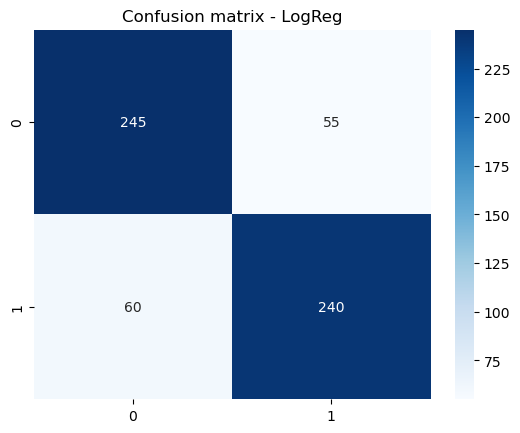


LinearSVM: Acc=0.798 Prec=0.795 Rec=0.803 F1=0.799
              precision    recall  f1-score   support

           0       0.80      0.79      0.80       300
           1       0.80      0.80      0.80       300

    accuracy                           0.80       600
   macro avg       0.80      0.80      0.80       600
weighted avg       0.80      0.80      0.80       600



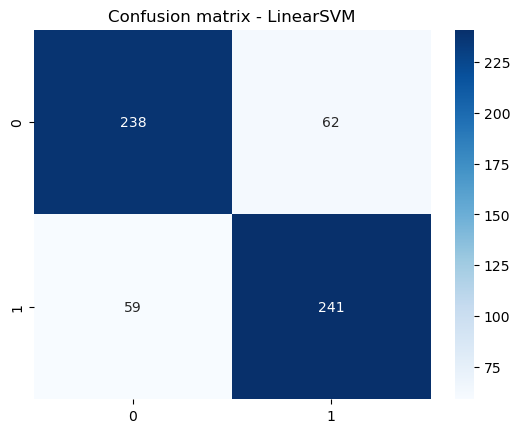

In [16]:
models = {"LogReg": LogisticRegression(max_iter=1000), "LinearSVM": LinearSVC()}
for name, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict(Xte)
    print(f"\n{name}: Acc={accuracy_score(y_test,p):.3f} Prec={precision_score(y_test,p):.3f} "
          f"Rec={recall_score(y_test,p):.3f} F1={f1_score(y_test,p):.3f}")
    print(classification_report(y_test, p))
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion matrix - {name}"); plt.show()

In [17]:
best = models["LogReg"]
for s in ["This phone is absolutely amazing!",
          "Worst service ever, totally disappointed.",
          "The food was okay."]:
    pred = best.predict(vec.transform([clean(s)]))[0]
    print(s, "->", "Positive" if pred == 1 else "Negative")

This phone is absolutely amazing! -> Positive
Worst service ever, totally disappointed. -> Negative
The food was okay. -> Negative
